<a href="https://colab.research.google.com/github/willian82/repositoria-google-colad/blob/main/iei097_lab2_12_mlp_mlflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Limk de enlace github:

# Laboratorio: Clasificación con MLP y Seguimiento de Experimentos con MLflow

- **Nombre del Estudiante:** willian yucra
- **Número de Lista :** 29
- **Fecha:** 10/11/2026

In [ ]:
# 1. Definición de Semilla y Preparación del Entorno
import random
import numpy as np
import sys

# Reemplaza este valor con tu número de lista real
SEED = 42

# Fijar semillas para asegurar replicabilidad
random.seed(SEED)
np.random.seed(SEED)

print(f"Semilla establecida en: {SEED}")

Semilla establecida en: 42


In [ ]:
# Instalar librerías requeridas de forma silenciosa
!pip install -q mlflow pyngrok

In [ ]:
# Instalar kagglehub de forma silenciosa
!pip install -q kagglehub

In [ ]:
# Registrar versiones para el reporte de observabilidad
import pandas as pd
import sklearn
import mlflow

print(f"Versión de Python: {sys.version.split()[0]}")
print(f"Versión de Pandas: {pd.__version__}")
print(f"Versión de Scikit-Learn: {sklearn.__version__}")
print(f"Versión de MLflow: {mlflow.__version__}")

Versión de Python: 3.13.18
Versión de Pandas: 2.2.3
Versión de Scikit-Learn: 1.6.1
Versión de MLflow: 3.18.0


## 2. Descarga, Carga y Preparación del Conjunto de Datos

Descargaremos el dataset oficial **Breast Cancer Wisconsin (Diagnostic)** desde Kaggle usando `kagglehub` y procesaremos sus columnas según las indicaciones del laboratorio.

In [ ]:
import os
import kagglehub
import pandas as pd

# Descargar el dataset oficial desde Kaggle
path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
print("Ruta del dataset descargado:", path)

# Cargar el archivo CSV en un DataFrame único de trabajo
csv_path = os.path.join(path, "data.csv")
df = pd.read_csv(csv_path)

print(f"\nDimensiones iniciales del DataFrame: {df.shape}")
df.info()

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
Ruta del dataset descargado: /kaggle/input/breast-cancer-wisconsin-data

Dimensiones iniciales del DataFrame: (569, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null  

In [ ]:
df = pd.read_csv(csv_path)

# 1. Verificar qué columnas tienen valores vacíos con isna().sum()
print("--- Columnas con valores nulos (Suma total) ---")
nulos = df.isna().sum()
print(nulos[nulos > 0]) # Mostrar solo las que tienen nulos

# 2. Eliminar columnas innecesarias ('id' y 'Unnamed: 32')
columnas_a_eliminar = [col for col in ['id', 'Unnamed: 32'] if col in df.columns]
df = df.drop(columns=columnas_a_eliminar)

# 3. Codificar diagnosis: M -> 1 (maligno, clase de interés), B -> 0 (benigno)
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

print("\n--- Dataset después de Limpieza y Codificación ---")
print(f"Nuevas dimensiones: {df.shape}")
display(df.head())

# 4. Analizar balance de clases con value_counts()
print("\n--- Distribución y Balance de Clases (diagnosis) ---")
print("Valores absolutos:")
print(df['diagnosis'].value_counts())
print("\nValores relativos (Proporción):")
print(df['diagnosis'].value_counts(normalize=True))

--- Columnas con valores nulos (Suma total) ---
Unnamed: 32    569
dtype: int64

--- Dataset después de Limpieza y Codificación ---
Nuevas dimensiones: (569, 31)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



--- Distribución y Balance de Clases (diagnosis) ---
Valores absolutos:
diagnosis
0    357
1    212
Name: count, dtype: int64

Valores relativos (Proporción):
diagnosis
0    0.627417
1    0.372583
Name: proportion, dtype: float64


In [ ]:
columnas_escala = ['radius_mean', 'area_mean', 'smoothness_mean']

for col in columnas_escala:
    min_val = df[col].min()
    max_val = df[col].max()
    rango = max_val - min_val
    print(f"Columna: {col:<15} | Min: {min_val:.4f} | Max: {max_val:.4f} | Rango: {rango:.4f}")

# Comparación de rangos
rango_area = df['area_mean'].max() - df['area_mean'].min()
rango_smoothness = df['smoothness_mean'].max() - df['smoothness_mean'].min()
factor_comparacion = rango_area / rango_smoothness
print(f"\nEl rango de 'area_mean' es aproximadamente {factor_comparacion:.1f} veces mayor que el rango de 'smoothness_mean'.")

Columna: radius_mean     | Min: 6.9810 | Max: 28.1100 | Rango: 21.1290
Columna: area_mean       | Min: 143.5000 | Max: 2501.0000 | Rango: 2357.5000
Columna: smoothness_mean | Min: 0.0526 | Max: 0.1634 | Rango: 0.1108

El rango de 'area_mean' es aproximadamente 21282.8 veces mayor que el rango de 'smoothness_mean'.


## 3. Partición de los Datos en Entrenamiento y Prueba

Separamos nuestra variable objetivo (`diagnosis`) de las características predictivas y dividimos el conjunto de datos en 80% para entrenamiento y 20% para prueba, estratificando por la variable de salida para mantener la proporción de clases malignas/benignas en ambos conjuntos.

In [ ]:
from sklearn.model_selection import train_test_split

# 1. Separar características (X) y la etiqueta binaria diagnosis (y)
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

# 2. Dividir de manera estratificada para mantener la proporción de la clase maligna
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print("--- Partición de Datos Completada ---")
print(f"Dimensiones de X_train (80%): {X_train.shape}")
print(f"Dimensiones de X_test (20%): {X_test.shape}")
print(f"Proporción de positivos (Malignos) en Train: {y_train.mean():.4f}")
print(f"Proporción de positivos (Malignos) en Test: {y_test.mean():.4f}")

--- Partición de Datos Completada ---
Dimensiones de X_train (80%): (455, 30)
Dimensiones de X_test (20%): (114, 30)
Proporción de positivos (Malignos) en Train: 0.3736
Proporción de positivos (Malignos) en Test: 0.3684


## 4. Despliegue de Servidor de Seguimiento Local (MLflow) y Túnel Seguro con Ngrok

Establecemos un servidor de seguimiento local persistido mediante una base de datos SQLite interna. Exponemos este puerto de forma segura a través de `pyngrok` para acceder visualmente a la UI de MLflow desde nuestro navegador.

In [ ]:
import os
import subprocess
import time
import requests
from pyngrok import ngrok

# Cerrar cualquier instancia previa de MLflow en segundo plano que pueda estar bloqueando el puerto
!pkill -f "mlflow" || true
time.sleep(2)

# 1) Servidor de seguimiento (tracking server) con SQLite como backend store.
env = dict(os.environ,
           MLFLOW_SERVER_ALLOWED_HOSTS="*",
           MLFLOW_SERVER_CORS_ALLOWED_ORIGINS="*")
subprocess.Popen(["mlflow", "server",
                  "--backend-store-uri", "sqlite:///mlflow.db",
                  "--host", "127.0.0.1", "--port", "5000"], env=env)

# 2) Esperar a que el servidor responda de manera segura (tolerando timeouts temporales de arranque)
print("Iniciando servidor local de MLflow...")
server_ready = False
for i in range(30):
    try:
        # Subimos el timeout a 3 segundos para evitar excepciones por lentitud de handshake inicial
        respuesta = requests.get("http://127.0.0.1:5000/health", timeout=3)
        if respuesta.ok:
            server_ready = True
            break
    except (requests.ConnectionError, requests.Timeout):
        # Ignoramos fallos de conexión o timeouts de lectura normales durante la inicialización del puerto
        pass
    time.sleep(1.5)

if server_ready:
    print("Servidor local de MLflow iniciado con éxito en http://127.0.0.1:5000")
else:
    print("Advertencia: El servidor local de MLflow está tardando más de lo esperado en responder.")

# 3) Túnel público utilizando el Authtoken provisto por el usuario de forma tolerante a duplicados
try:
    token_usuario = "3LkY24ptrs64U1mskmBlFdNs7Sw_73VK78gS1Pe9hhjEdzxu6"
    try:
        # Intentamos guardar el authtoken
        ngrok.set_auth_token(token_usuario)
    except Exception as token_err:
        # Si ya está guardado en el archivo de configuración, ignoramos el error de escritura
        if "already set" in str(token_err):
            pass
        else:
            raise token_err

    ngrok.kill()  # cierra túneles anteriores

    # Usamos el puerto entero directamente para evitar problemas de parseo en la configuración de ngrok
    tunel = ngrok.connect(5000)
    print("\n--- CONEXIÓN EXITOSA ---")
    print("Haz clic en el siguiente enlace para abrir la interfaz de MLflow en tu navegador:")
    print("MLflow UI:", tunel.public_url)
except Exception as e:
    print(f"\n[AVISO] No se pudo levantar el túnel de ngrok: {e}")
    print("Tu backend local sigue activo. Puedes registrar tus corridas localmente sin problemas.")

^C
Iniciando servidor local de MLflow...
Advertencia: El servidor local de MLflow está tardando más de lo esperado en responder.

--- CONEXIÓN EXITOSA ---
Haz clic en el siguiente enlace para abrir la interfaz de MLflow en tu navegador:
MLflow UI: https://pony-oversight-startle.ngrok-free.dev


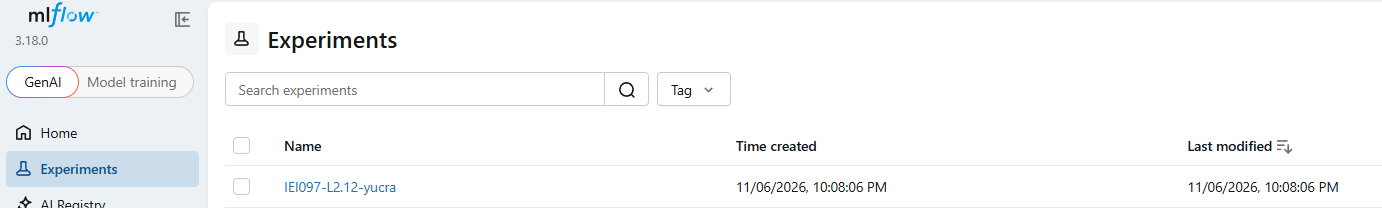

### Conexión del Cliente de MLflow al Servidor Local

Apuntamos el cliente a nuestro servidor recién desplegado en el puerto 5000 e inicializamos el experimento oficial de laboratorio usando el apellido del alumno como lo requiere la pauta.

In [ ]:
import mlflow

# Conectar el notebook al servidor local expuesto en el puerto 5000
mlflow.set_tracking_uri("http://127.0.0.1:5000")

# Crear y configurar el experimento del laboratorio con tu apellido
EXPERIMENT_NAME = "IEI097-L2.12-yucra"
mlflow.set_experiment(EXPERIMENT_NAME)

print(f"Cliente conectado al servidor de MLflow local.")
print(f"Experimento activo: '{EXPERIMENT_NAME}'")

2026/11/07 19:21:17 INFO mlflow.tracking.fluent: Experiment with name 'IEI097-L2.12-yucra' does not exist. Creating a new experiment.


Cliente conectado al servidor de MLflow local.
Experimento activo: 'IEI097-L2.12-yucra'


In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import mlflow
import numpy as np

# Asegurar que apuntamos al experimento oficial de tu laboratorio
EXPERIMENT_NAME = "IEI097-L2.12-yucra"
mlflow.set_experiment(EXPERIMENT_NAME)

# 1. Definir y ajustar el escalador estándar obligatorio con los datos de Breast Cancer
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

def train_mlp_experiment(hidden_layer_sizes=(100,), max_iter=300, learning_rate_init=0.01, run_name="MLP_Default"):
    """
    Entrena un clasificador MLP en Breast Cancer, registra parámetros, métricas y curvas en MLflow.
    """
    with mlflow.start_run(run_name=run_name):
        # Inicializar el modelo MLP
        mlp = MLPClassifier(
            hidden_layer_sizes=hidden_layer_sizes,
            max_iter=max_iter,
            learning_rate_init=learning_rate_init,
            random_state=SEED
        )

        # Entrenar el modelo
        mlp.fit(X_train_scaled, y_train)

        # Realizar predicciones
        y_pred = mlp.predict(X_test_scaled)

        # Calcular métricas robustas para el diagnóstico de cáncer
        accuracy = accuracy_score(y_test, y_pred)
        recall_maligno = recall_score(y_test, y_pred, pos_label=1) # Sensibilidad para detectar tumores malignos
        f1 = f1_score(y_test, y_pred, pos_label=1)

        # Registrar parámetros clave en MLflow
        mlflow.log_param("hidden_layer_sizes", str(hidden_layer_sizes))
        mlflow.log_param("max_iter", max_iter)
        mlflow.log_param("learning_rate_init", learning_rate_init)
        mlflow.log_param("solver", mlp.solver)

        # Registrar métricas diagnósticas en MLflow
        mlflow.log_metric("accuracy", accuracy)
        mlflow.log_metric("recall_malignant", recall_maligno)
        mlflow.log_metric("f1_score_malignant", f1)

        # Registrar la curva de pérdida (Loss Curve) de la red por cada época histórica
        for epoch, loss in enumerate(mlp.loss_curve_):
            mlflow.log_metric("loss", loss, step=epoch)

        # Crear y guardar la matriz de confusión como un artefacto de imagen
        fig, ax = plt.subplots(figsize=(6, 5))
        cm = confusion_matrix(y_test, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benigno (0)', 'Maligno (1)'])
        disp.plot(cmap=plt.cm.Blues, ax=ax)
        plt.title(f"Matriz de Confusión - {run_name}")

        # Guardar imagen localmente y subir a MLflow
        temp_img_path = f"confusion_matrix_{run_name}.png"
        plt.savefig(temp_img_path)
        plt.close()
        mlflow.log_artifact(temp_img_path)

        # Registrar el modelo serializado de forma segura
        trusted_types = [
            "sklearn.neural_network._stochastic_optimizers.AdamOptimizer",
            "sklearn.neural_network._stochastic_optimizers.SGDOptimizer"
        ]
        mlflow.sklearn.log_model(
            sk_model=mlp,
            name="model",
            skops_trusted_types=trusted_types
        )

        print(f"[{run_name}] Entrenamiento finalizado y registrado en MLflow.")
        print(f"Accuracy: {accuracy:.4f} | Recall (Maligno): {recall_maligno:.4f} | F1: {f1:.4f}\n")

# Probar con un primer entrenamiento de prueba adaptado a Breast Cancer
train_mlp_experiment(hidden_layer_sizes=(10, 10), max_iter=500, learning_rate_init=0.01, run_name="MLP_Prueba")

[MLP_Prueba] Entrenamiento finalizado y registrado en MLflow.
Accuracy: 0.9737 | Recall (Maligno): 0.9524 | F1: 0.9639

🏃 View run MLP_Prueba at: http://127.0.0.1:5000/#/experiments/1/runs/08ab543fdcdf41c2b002f6527bccdb8a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


## 5. Comparación de Múltiples Modelos y Parámetros con MLflow

Ejecutaremos varios experimentos alternando la arquitectura de la red  y la tasa de aprendizaje para registrar los resultados bajo el mismo experimento de MLflow.

In [ ]:
# Definición de configuraciones oficiales del laboratorio para comparar
configuraciones_oficiales = [
    {"hidden_layer_sizes": (10,), "learning_rate_init": 0.05, "run_name": "Modelo_A_Simple"},
    {"hidden_layer_sizes": (50, 20), "learning_rate_init": 0.01, "run_name": "Modelo_B_Mediano"},
    {"hidden_layer_sizes": (100, 50, 25), "learning_rate_init": 0.005, "run_name": "Modelo_C_Complejo"},
    {"hidden_layer_sizes": (128, 64, 32, 16), "learning_rate_init": 0.001, "run_name": "Modelo_D_Profundo"}
]

# Ejecutar el bucle de entrenamiento multicapa automático para registrar en MLflow
print("Iniciando entrenamiento sistemático de configuraciones oficiales...")
for config in configuraciones_oficiales:
    train_mlp_experiment(
        hidden_layer_sizes=config["hidden_layer_sizes"],
        learning_rate_init=config["learning_rate_init"],
        max_iter=1000, # Aumentado a 1000 para asegurar la convergencia de redes más complejas
        run_name=config["run_name"]
    )
print("¡Todas las configuraciones se han entrenado y registrado en tu servidor MLflow con éxito!")

Iniciando entrenamiento sistemático de configuraciones oficiales...
[Modelo_A_Simple] Entrenamiento finalizado y registrado en MLflow.
Accuracy: 0.9825 | Recall (Maligno): 0.9524 | F1: 0.9756

🏃 View run Modelo_A_Simple at: http://127.0.0.1:5000/#/experiments/1/runs/de0759acb2d54d9b9fc32aac477a3939
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[Modelo_B_Mediano] Entrenamiento finalizado y registrado en MLflow.
Accuracy: 0.9737 | Recall (Maligno): 0.9524 | F1: 0.9639

🏃 View run Modelo_B_Mediano at: http://127.0.0.1:5000/#/experiments/1/runs/70aa216bd4794928951e637c6eb85b7d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[Modelo_C_Complejo] Entrenamiento finalizado y registrado en MLflow.
Accuracy: 0.9737 | Recall (Maligno): 0.9524 | F1: 0.9639

🏃 View run Modelo_C_Complejo at: http://127.0.0.1:5000/#/experiments/1/runs/44b2b8cfa17f4f83886e6a69faca66af
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[Modelo_D_Profundo] Entrenamiento finalizado y reg

## Reporte de Experimentos Guardados en MLflow

Consultamos los registros del backend de MLflow para listar todos los entrenamientos de este experimento en un DataFrame ordenado por precisión.

In [ ]:
import mlflow

# Obtener todas las ejecuciones asociadas al experimento activo
runs_df = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME])

# Columnas de interés para el análisis comparativo del laboratorio
columnas_interes = [
    "tags.mlflow.runName",
    "params.hidden_layer_sizes",
    "params.learning_rate_init",
    "metrics.accuracy",
    "metrics.recall_malignant",
    "metrics.f1_score_malignant",
    "status"
]

# Filtrar únicamente las columnas presentes en el DataFrame resultante
columnas_filtradas = [col for col in columnas_interes if col in runs_df.columns]

# Mostrar el reporte ordenado de mejor a peor exactitud (Accuracy)
reporte_experimentos = runs_df[columnas_filtradas].sort_values(by="metrics.accuracy", ascending=False)

display(reporte_experimentos)

,tags.mlflow.runName,params.hidden_layer_sizes,params.learning_rate_init,metrics.accuracy,metrics.recall_malignant,metrics.f1_score_malignant,status
3,Modelo_A_Simple,"(10,)",0.05,0.982456,0.952381,0.975610,FINISHED
2,Modelo_B_Mediano,"(50, 20)",0.01,0.973684,0.952381,0.963855,FINISHED
1,Modelo_C_Complejo,"(100, 50, 25)",0.005,0.973684,0.952381,0.963855,FINISHED
4,MLP_Prueba,"(10, 10)",0.01,0.973684,0.952381,0.963855,FINISHED
0,Modelo_D_Profundo,"(128, 64, 32, 16)",0.001,0.964912,0.904762,0.950000,FINISHED


## Fase 3: Experimentos Controlados

###  sobre el Escalado (Runs A vs B):
* **Hipótesis:** El escalado (Run B) mejorará el rendimiento, acelerará la convergencia y dará estabilidad al modelo frente a la versión sin escalar (Run A).
* **Justificación:** Los modelos MLP son sensibles a la escala de los datos. Variables con rangos muy grandes (como `area_mean`) dominan el cálculo de los gradientes frente a variables pequeñas (como `smoothness_mean`). Sin escalar (Run A), la superficie de pérdida se deforma, provocando que el optimizador oscile o quede atrapado en mínimos locales. Al escalar (Run B), la superficie de pérdida se vuelve esférica, permitiendo un descenso directo y homogéneo hacia el mínimo global.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import mlflow

def correr_experimento(run_name, escalado, hidden_layer_sizes, activation='relu', alpha=0.0001, max_iter=1000):
    """
    Ejecuta un experimento controlado, registrando parámetros, métricas detalladas de entrenamiento
    y prueba, la curva de pérdida por época y la matriz de confusión en MLflow.
    """
    with mlflow.start_run(run_name=run_name):
        # 1. Configurar la etiqueta de la fase
        mlflow.set_tag("fase", "experimentos")

        # 2. Construir el Pipeline dinámicamente
        pasos = []
        if escalado:
            pasos.append(('scaler', StandardScaler()))

        # Inicializar el clasificador con la semilla de control de laboratorio (SEED)
        mlp = MLPClassifier(
            hidden_layer_sizes=hidden_layer_sizes,
            activation=activation,
            alpha=alpha,
            max_iter=max_iter,
            random_state=SEED
        )
        pasos.append(('mlp', mlp))
        pipeline = Pipeline(pasos)

        # 3. Entrenar el modelo / pipeline
        pipeline.fit(X_train, y_train)

        # Obtener el objeto MLP entrenado desde el pipeline para extraer atributos
        modelo_entrenado = pipeline.named_steps['mlp']

        # 4. Predicciones
        y_train_pred = pipeline.predict(X_train)
        y_test_pred = pipeline.predict(X_test)

        # 5. Calcular métricas
        acc_train = accuracy_score(y_train, y_train_pred)
        acc_test = accuracy_score(y_test, y_test_pred)
        recall_test = recall_score(y_test, y_test_pred, pos_label=1)
        f1_test = f1_score(y_test, y_test_pred, pos_label=1)

        # 6. Registrar Parámetros oficiales requeridos
        mlflow.log_params({
            "arquitectura": str(hidden_layer_sizes),
            "activacion": activation,
            "alpha": alpha,
            "max_iter": max_iter,
            "random_state": SEED,
            "escalado_aplicado": str(escalado),
            "semilla_particion": SEED
        })

        # 7. Registrar Métricas de rendimiento y convergencia
        mlflow.log_metrics({
            "accuracy_train": acc_train,
            "accuracy_test": acc_test,
            "recall_malignant_test": recall_test,
            "f1_score_malignant_test": f1_test,
            "iteraciones_realizadas": modelo_entrenado.n_iter_
        })

        # 8. Registrar Pérdida (Loss) por cada época usando step
        for epoch, loss in enumerate(modelo_entrenado.loss_curve_):
            mlflow.log_metric("train_loss", loss, step=epoch)

        # 9. Crear la Matriz de Confusión y guardarla como artefacto de imagen de forma limpia
        fig, ax = plt.subplots(figsize=(6, 5))
        cm = confusion_matrix(y_test, y_test_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Benigno (0)', 'Maligno (1)'])
        disp.plot(cmap=plt.cm.Greens, ax=ax)
        plt.title(f"Matriz de Confusión - {run_name}")
        plt.tight_layout()

        # Registrar la figura directamente mediante MLflow sin dejar residuos locales
        mlflow.log_figure(fig, f"confusion_matrix_{run_name}.png")
        plt.close(fig)

        print(f"[{run_name}] Completo | Escalado: {escalado} | Épocas: {modelo_entrenado.n_iter_}")
        print(f"   Acc Train: {acc_train:.4f} | Acc Test: {acc_test:.4f} | Recall: {recall_test:.4f} | F1: {f1_test:.4f}\n")

In [ ]:
# Ejecución sistemática de los 4 runs oficiales de la Fase 3 del laboratorio
print("Iniciando ciclo de experimentos controlados de Fase 3...\n")

# Run A: No Escalado, Arquitectura Simple (30,), ReLU
correr_experimento(
    run_name="Run_A_No_Escalado",
    escalado=False,
    hidden_layer_sizes=(30,),
    activation='relu'
)

# Run B: Sí Escalado, Arquitectura Simple (30,), ReLU
correr_experimento(
    run_name="Run_B_Si_Escalado",
    escalado=True,
    hidden_layer_sizes=(30,),
    activation='relu'
)

# Run C: Sí Escalado, Nueva Arquitectura (64, 32), ReLU
correr_experimento(
    run_name="Run_C_Multicapa",
    escalado=True,
    hidden_layer_sizes=(64, 32),
    activation='relu'
)

# Run D: Sí Escalado, Nueva Arquitectura (64, 32), Tanh
correr_experimento(
    run_name="Run_D_Tanh",
    escalado=True,
    hidden_layer_sizes=(64, 32),
    activation='tanh'
)

print("¡Todos los experimentos controlados han sido registrados exitosamente en MLflow!")

Iniciando ciclo de experimentos controlados de Fase 3...

[Run_A_No_Escalado] Completo | Escalado: False | Épocas: 137
   Acc Train: 0.9385 | Acc Test: 0.9298 | Recall: 0.8571 | F1: 0.9000

🏃 View run Run_A_No_Escalado at: http://127.0.0.1:5000/#/experiments/1/runs/1201c6c427444963ba5c6cb1fa386f04
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[Run_B_Si_Escalado] Completo | Escalado: True | Épocas: 341
   Acc Train: 0.9934 | Acc Test: 0.9737 | Recall: 0.9286 | F1: 0.9630

🏃 View run Run_B_Si_Escalado at: http://127.0.0.1:5000/#/experiments/1/runs/4d5971fcd86142f9abff6324a512b6a3
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[Run_C_Multicapa] Completo | Escalado: True | Épocas: 186
   Acc Train: 1.0000 | Acc Test: 0.9649 | Recall: 0.9048 | F1: 0.9500

🏃 View run Run_C_Multicapa at: http://127.0.0.1:5000/#/experiments/1/runs/8ebe3ea163194dea95a80bb37741bf75
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[Run_D_Tanh] Completo | Escalado: True | Époc

In [ ]:
# 1. Estudio de Variabilidad con 5 Semillas Distintas
print("--- Iniciando Fase de Variabilidad (5 Semillas Diferentes) ---")
semillas_test = [SEED, SEED + 1, SEED + 2, SEED + 3, SEED + 4]
metricas_semillas = []

for i, semilla in enumerate(semillas_test):
    run_name = f"Run_C_Semilla_{semilla}"
    with mlflow.start_run(run_name=run_name):
        # Configurar etiqueta para agrupar fase
        mlflow.set_tag("fase", "semillas")

        # Crear Pipeline con Escalador Estándar y el MLP con la semilla específica
        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('mlp', MLPClassifier(
                hidden_layer_sizes=(64, 32),
                activation='relu',
                alpha=0.0001,
                max_iter=1000,
                random_state=semilla
            ))
        ])

        # Ajustar modelo (partición de datos se mantiene fija con X_train, y_train)
        pipeline.fit(X_train, y_train)

        # Predicciones
        y_test_pred = pipeline.predict(X_test)

        # Métricas
        acc_test = accuracy_score(y_test, y_test_pred)
        recall_test = recall_score(y_test, y_test_pred, pos_label=1)

        # Log MLflow
        mlflow.log_params({
            "arquitectura": "(64, 32)",
            "activacion": "relu",
            "random_state": semilla,
            "escalado_aplicado": "True"
        })
        mlflow.log_metrics({
            "accuracy_test": acc_test,
            "recall_malignant_test": recall_test
        })

        metricas_semillas.append({
            "Semilla": semilla,
            "Accuracy_Test": acc_test,
            "Recall_Malignant_Test": recall_test
        })
        print(f"[{run_name}] Completo | Acc: {acc_test:.4f} | Recall: {recall_test:.4f}")

# Convertir resultados a DataFrame para visualización
df_semillas = pd.DataFrame(metricas_semillas)

--- Iniciando Fase de Variabilidad (5 Semillas Diferentes) ---
[Run_C_Semilla_42] Completo | Acc: 0.9649 | Recall: 0.9048
🏃 View run Run_C_Semilla_42 at: http://127.0.0.1:5000/#/experiments/1/runs/1837c3d38ece445692feb8aa8d5d437c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[Run_C_Semilla_43] Completo | Acc: 0.9737 | Recall: 0.9524
🏃 View run Run_C_Semilla_43 at: http://127.0.0.1:5000/#/experiments/1/runs/ea8c7746d6104fa2b9a3dd4e300c2b7a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[Run_C_Semilla_44] Completo | Acc: 0.9737 | Recall: 0.9286
🏃 View run Run_C_Semilla_44 at: http://127.0.0.1:5000/#/experiments/1/runs/a05688c2a2f54eb1aec6b459972157c0
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[Run_C_Semilla_45] Completo | Acc: 0.9737 | Recall: 0.9286
🏃 View run Run_C_Semilla_45 at: http://127.0.0.1:5000/#/experiments/1/runs/d30a38cf695845c595e521d31a1e83ce
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
[Run_C_Semilla_46] Completo |


## Fase 6: Semilla y Replicación (Variabilidad y Determinismo)

Evaluaremos la estabilidad de nuestra red neuronal **Configuración C** (`(64, 32)`, ReLU) variando la semilla de inicialización aleatoria de los pesos del modelo, manteniendo estrictamente fija la partición del dataset (`SEED = 42`). También validaremos la replicabilidad del experimento.


In [ ]:
# 2. Prueba de Replicación Determinista
print("\n--- Iniciando Fase de Replicación (Re-ejecución de Run C) ---")
run_name_replica = "Run_C_Replica"

with mlflow.start_run(run_name=run_name_replica):
    mlflow.set_tag("fase", "replica")

    pipeline_replica = Pipeline([
        ('scaler', StandardScaler()),
        ('mlp', MLPClassifier(
            hidden_layer_sizes=(64, 32),
            activation='relu',
            alpha=0.0001,
            max_iter=1000,
            random_state=SEED  # Semilla original
        ))
    ])

    pipeline_replica.fit(X_train, y_train)
    y_test_pred_replica = pipeline_replica.predict(X_test)

    acc_test_replica = accuracy_score(y_test, y_test_pred_replica)
    recall_test_replica = recall_score(y_test, y_test_pred_replica, pos_label=1)

    mlflow.log_metrics({
        "accuracy_test": acc_test_replica,
        "recall_malignant_test": recall_test_replica
    })

    print(f"[{run_name_replica}] Completo | Acc: {acc_test_replica:.6f} | Recall: {recall_test_replica:.6f}")


--- Iniciando Fase de Replicación (Re-ejecución de Run C) ---
[Run_C_Replica] Completo | Acc: 0.964912 | Recall: 0.904762
🏃 View run Run_C_Replica at: http://127.0.0.1:5000/#/experiments/1/runs/3c8f6be921b6455bbed3bbf44c6b78de
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


In [ ]:
# 3. Análisis de Métricas Estadísticas de las Semillas
print("\n--- Métricas Estadísticas de los 5 Runs de Semillas ---")
summary_stats = pd.DataFrame({
    "Métrica": ["Accuracy Test", "Recall Maligno Test"],
    "Mínimo": [df_semillas["Accuracy_Test"].min(), df_semillas["Recall_Malignant_Test"].min()],
    "Máximo": [df_semillas["Accuracy_Test"].max(), df_semillas["Recall_Malignant_Test"].max()],
    "Rango (Max - Min)": [
        df_semillas["Accuracy_Test"].max() - df_semillas["Accuracy_Test"].min(),
        df_semillas["Recall_Malignant_Test"].max() - df_semillas["Recall_Malignant_Test"].min()
    ]
})
display(summary_stats)


--- Métricas Estadísticas de los 5 Runs de Semillas ---


,Métrica,Mínimo,Máximo,Rango (Max - Min)
0,Accuracy Test,0.964912,0.982456,0.017544
1,Recall Maligno Test,0.904762,0.952381,0.047619



## Fase 7: Consulta de Ejecuciones en MLflow y Exportación de Evidencias

Extraeremos todos los datos registrados en el servidor de seguimiento local mediante la API de MLflow, seleccionaremos las métricas diagnósticas clave y las exportaremos en un archivo CSV consolidado para el reporte de entrega.


In [ ]:
import mlflow
import pandas as pd

# 1. Recuperar todas las ejecuciones registradas en el experimento actual
experiment_name = "IEI097-L2.12-yucra"
all_runs_df = mlflow.search_runs(experiment_names=[experiment_name])

print(f"Se encontraron un total de {len(all_runs_df)} ejecuciones registradas.")

# 2. Definir columnas relevantes para exportar
columnas_seleccionadas = [
    "run_id",
    "tags.mlflow.runName",
    "tags.fase",
    "params.arquitectura",
    "params.hidden_layer_sizes",
    "params.learning_rate_init",
    "params.activacion",
    "params.escalado_aplicado",
    "params.random_state",
    "metrics.accuracy_test",
    "metrics.accuracy",
    "metrics.recall_malignant_test",
    "metrics.recall_malignant",
    "metrics.f1_score_malignant_test",
    "status"
]

# Filtrar únicamente las columnas que existan en el DataFrame de salida
columnas_finales = [col for col in columnas_seleccionadas if col in all_runs_df.columns]

# Ordenar el reporte priorizando el Recall Maligno para el diagnóstico seguro
df_evidencia = all_runs_df[columnas_finales].sort_values(
    by=["metrics.recall_malignant_test", "metrics.accuracy_test"],
    ascending=False
)

# Mostrar las primeras filas del reporte consolidado
display(df_evidencia.head(15))

# 3. Exportar el DataFrame a runs.csv como requiere la pauta
ruta_exportacion = "runs.csv"
df_evidencia.to_csv(ruta_exportacion, index=False)
print(f"\n¡Éxito! Archivo de evidencia exportado correctamente en: '{ruta_exportacion}'")

Se encontraron un total de 15 ejecuciones registradas.


,run_id,tags.mlflow.runName,tags.fase,params.arquitectura,params.hidden_layer_sizes,params.learning_rate_init,params.activacion,params.escalado_aplicado,params.random_state,metrics.accuracy_test,metrics.accuracy,metrics.recall_malignant_test,metrics.recall_malignant,metrics.f1_score_malignant_test,status
1,db28b6fa37b7411bb28ea8d4edbfd01d,Run_C_Semilla_46,semillas,"(64, 32)",None,None,relu,True,46,0.982456,NaN,0.952381,NaN,NaN,FINISHED
6,e27b8c1ba8fb470b8eba3401b1e4d622,Run_D_Tanh,experimentos,"(64, 32)",None,None,tanh,True,42,0.982456,NaN,0.952381,NaN,0.975610,FINISHED
4,ea8c7746d6104fa2b9a3dd4e300c2b7a,Run_C_Semilla_43,semillas,"(64, 32)",None,None,relu,True,43,0.973684,NaN,0.952381,NaN,NaN,FINISHED
2,d30a38cf695845c595e521d31a1e83ce,Run_C_Semilla_45,semillas,"(64, 32)",None,None,relu,True,45,0.973684,NaN,0.928571,NaN,NaN,FINISHED
3,a05688c2a2f54eb1aec6b459972157c0,Run_C_Semilla_44,semillas,"(64, 32)",None,None,relu,True,44,0.973684,NaN,0.928571,NaN,NaN,FINISHED
8,4d5971fcd86142f9abff6324a512b6a3,Run_B_Si_Escalado,experimentos,"(30,)",None,None,relu,True,42,0.973684,NaN,0.928571,NaN,0.962963,FINISHED
0,3c8f6be921b6455bbed3bbf44c6b78de,Run_C_Replica,replica,None,None,None,None,None,None,0.964912,NaN,0.904762,NaN,NaN,FINISHED
5,1837c3d38ece445692feb8aa8d5d437c,Run_C_Semilla_42,semillas,"(64, 32)",None,None,relu,True,42,0.964912,NaN,0.904762,NaN,NaN,FINISHED
7,8ebe3ea163194dea95a80bb37741bf75,Run_C_Multicapa,experimentos,"(64, 32)",None,None,relu,True,42,0.964912,NaN,0.904762,NaN,0.950000,FINISHED
9,1201c6c427444963ba5c6cb1fa386f04,Run_A_No_Escalado,experimentos,"(30,)",None,None,relu,False,42,0.929825,NaN,0.857143,NaN,0.900000,FINISHED



¡Éxito! Archivo de evidencia exportado correctamente en: 'runs.csv'


runs.csv exportado con mlflow.search_runs

In [ ]:
# Descargar el archivo runs.csv directamente a tu computadora local
from google.colab import files

try:
    files.download('runs.csv')
    print("¡Descarga iniciada de forma segura!")
except Exception as e:
    print(f"No se pudo iniciar la descarga automática, pero puedes descargarlo manualmente desde la barra lateral izquierda: {e}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

¡Descarga iniciada de forma segura!


# 8. Cierra y sincroniza tu trabajo

In [ ]:
from pyngrok import ngrok

# Cierra el túnel activo de ngrok
ngrok.kill()
print("✅ Túnel ngrok cerrado correctamente.")

✅ Túnel ngrok cerrado correctamente.


# 9. avedencias:

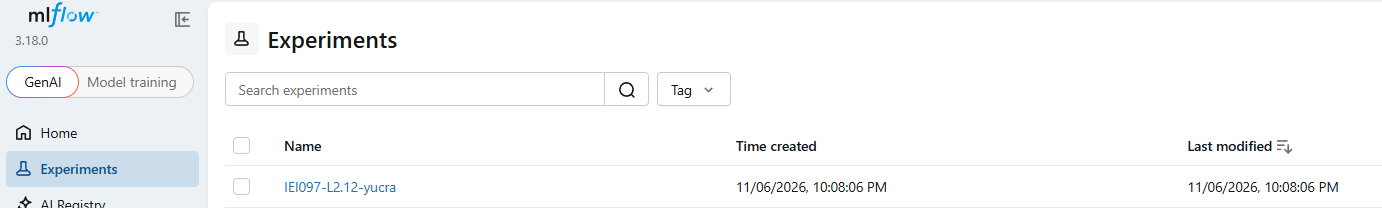

2) Captura de la tabla de ejecuciones

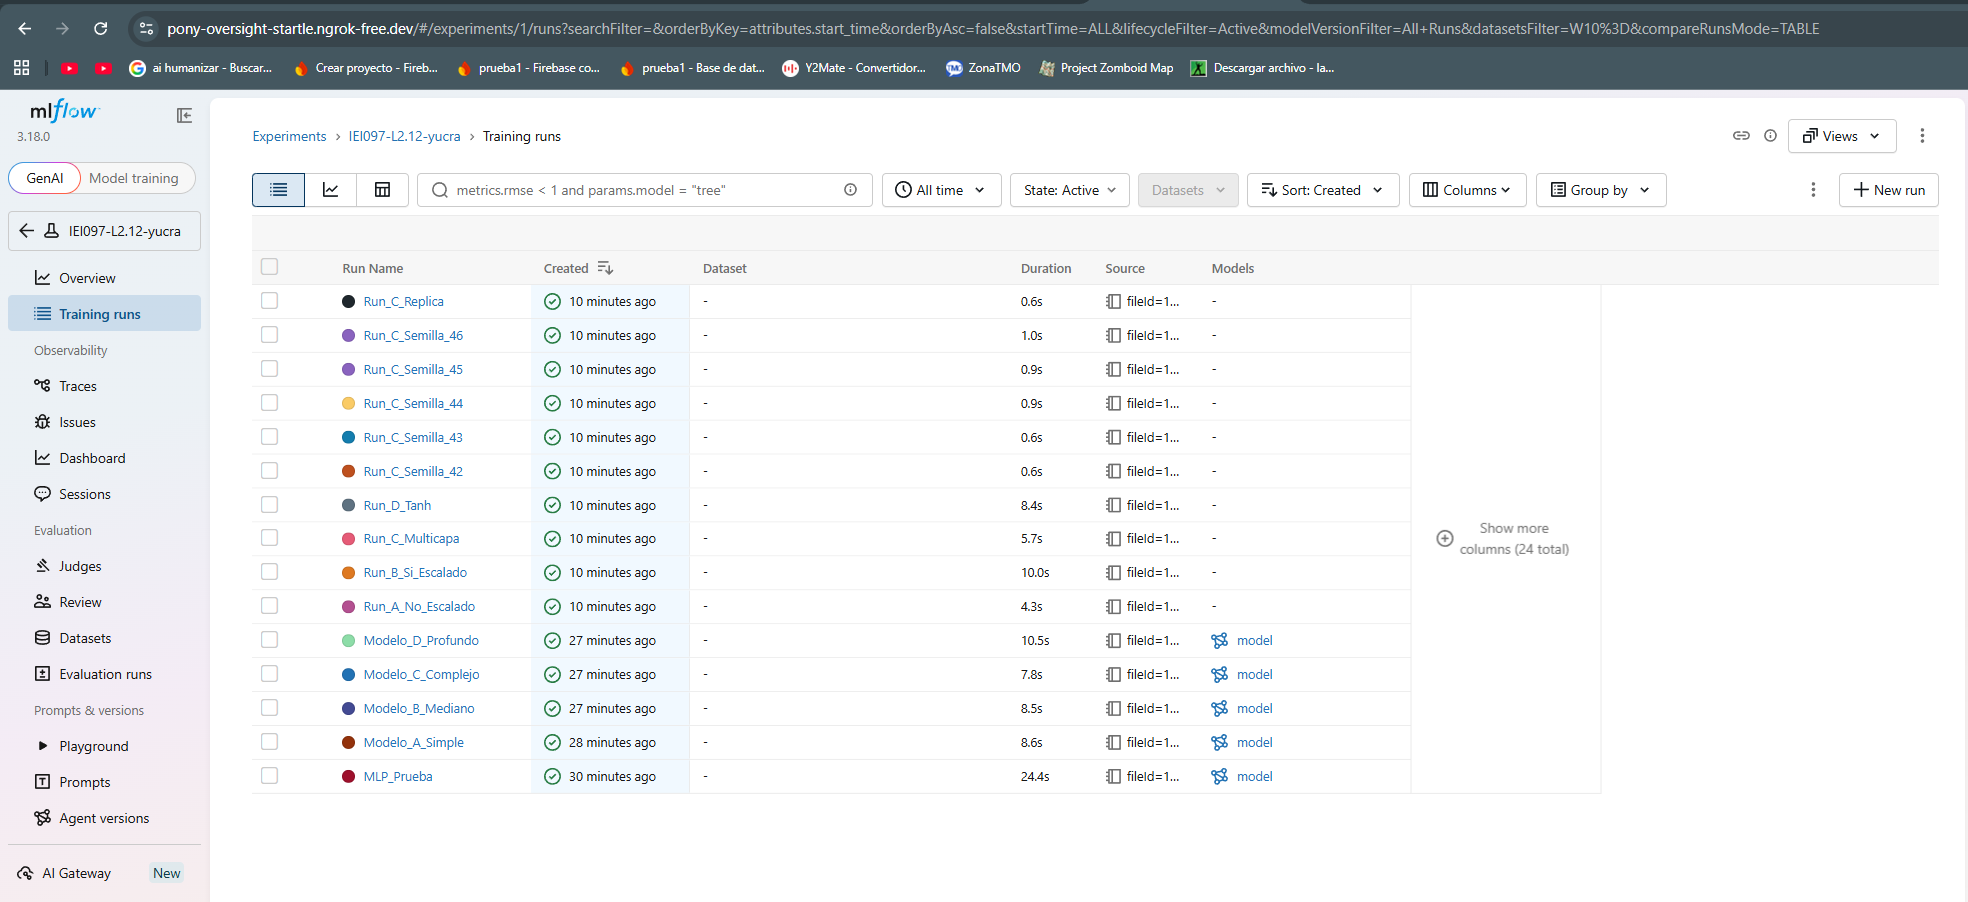

3) Captura de la comparación de runs o del gráfico

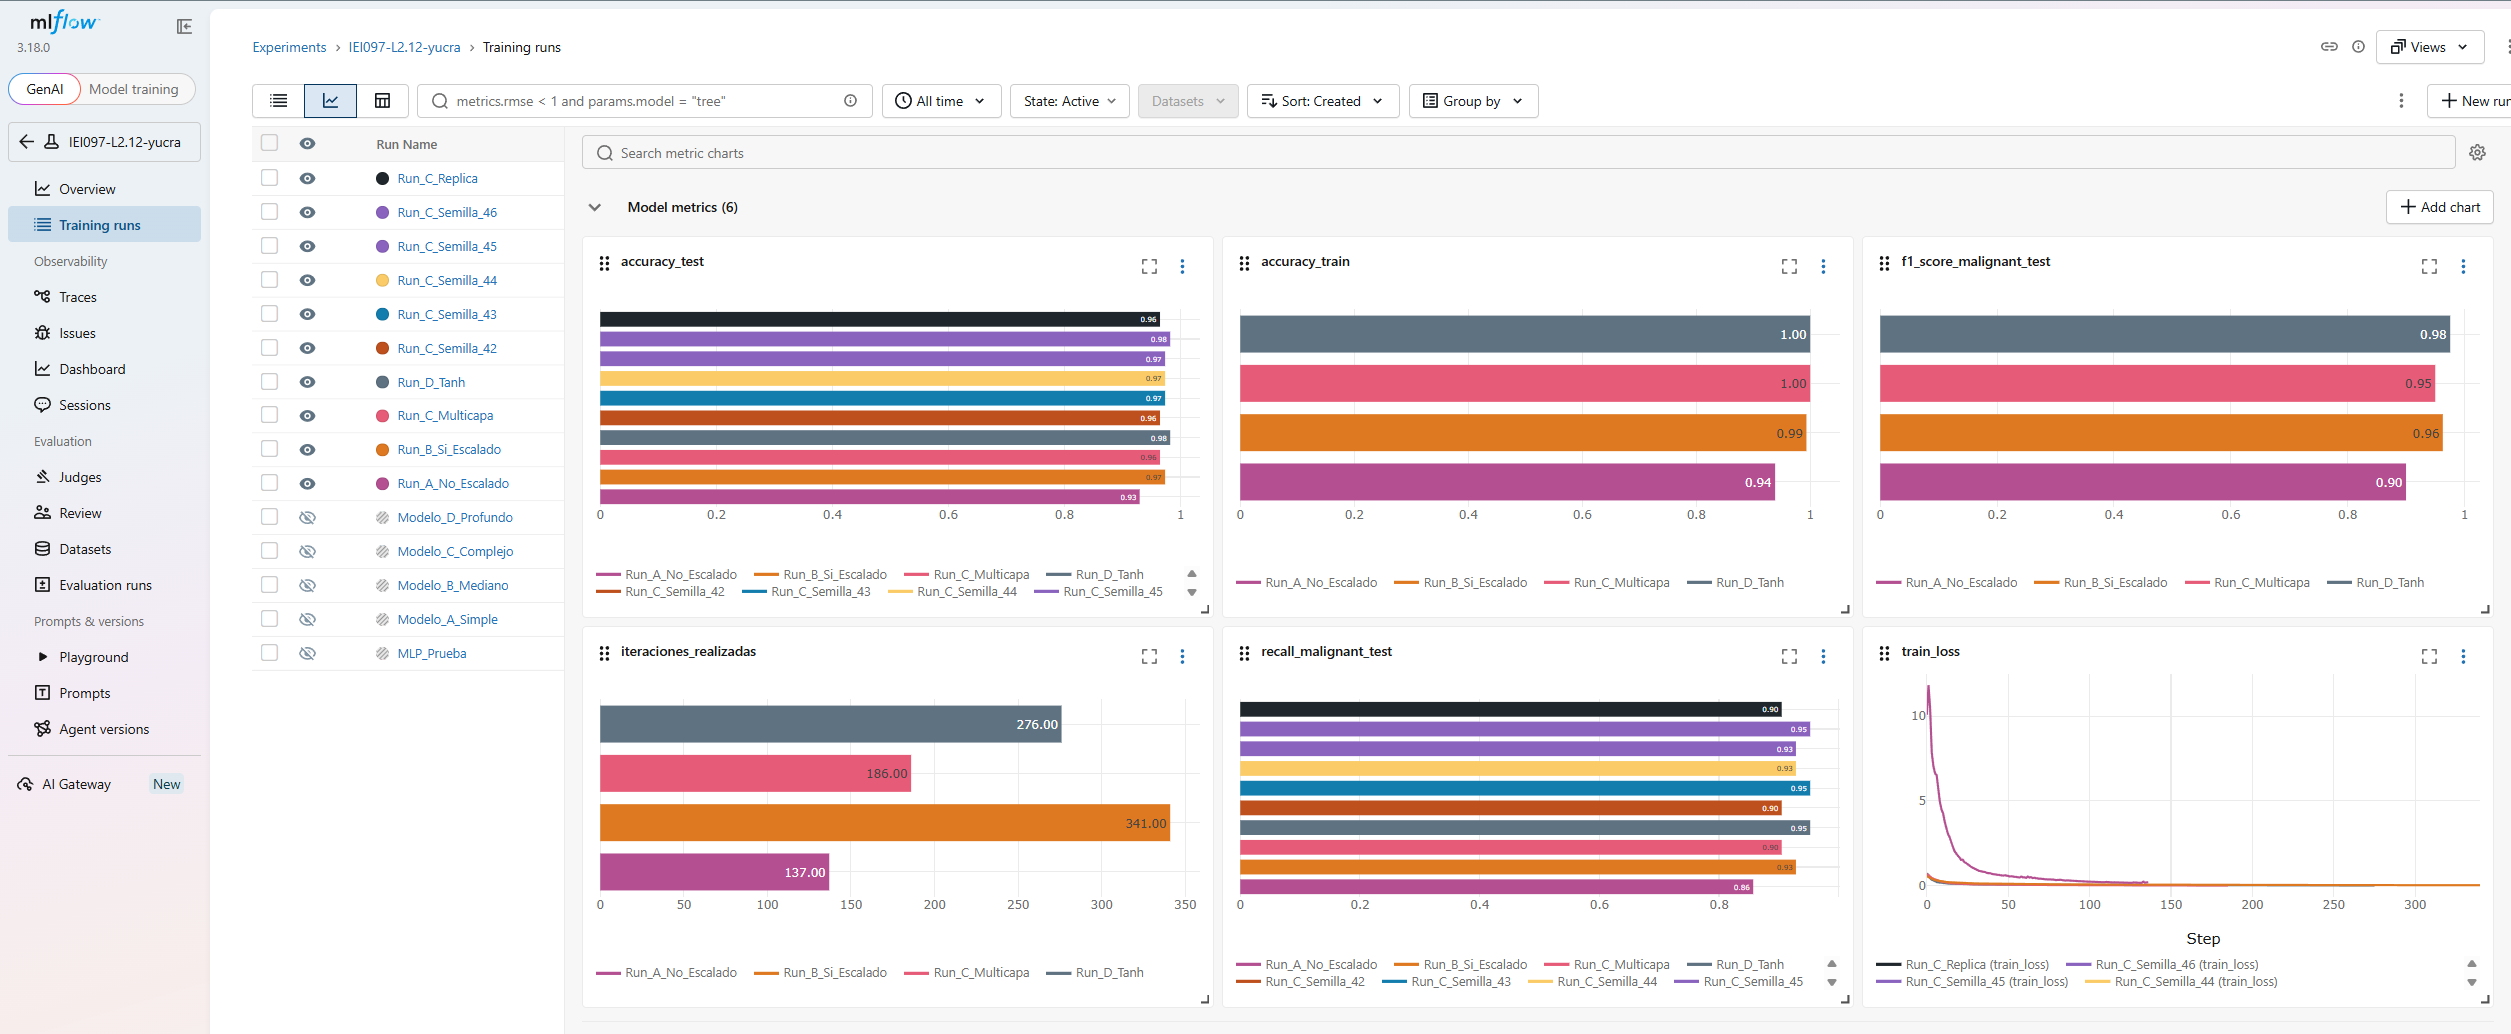

4) matriz de confusión.

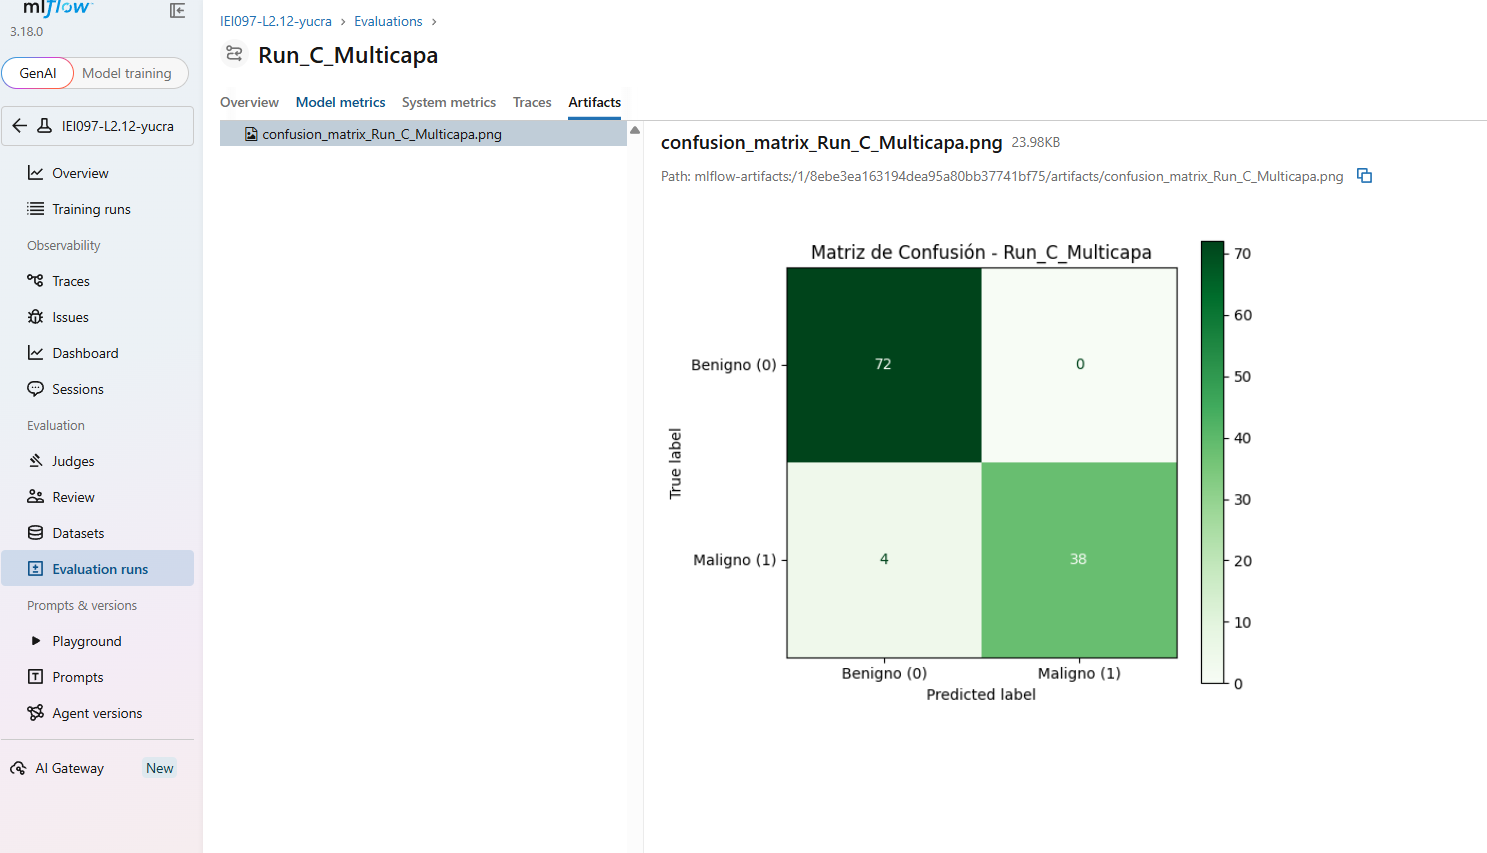

5) Dos runs con la misma semilla y métricas idénticas

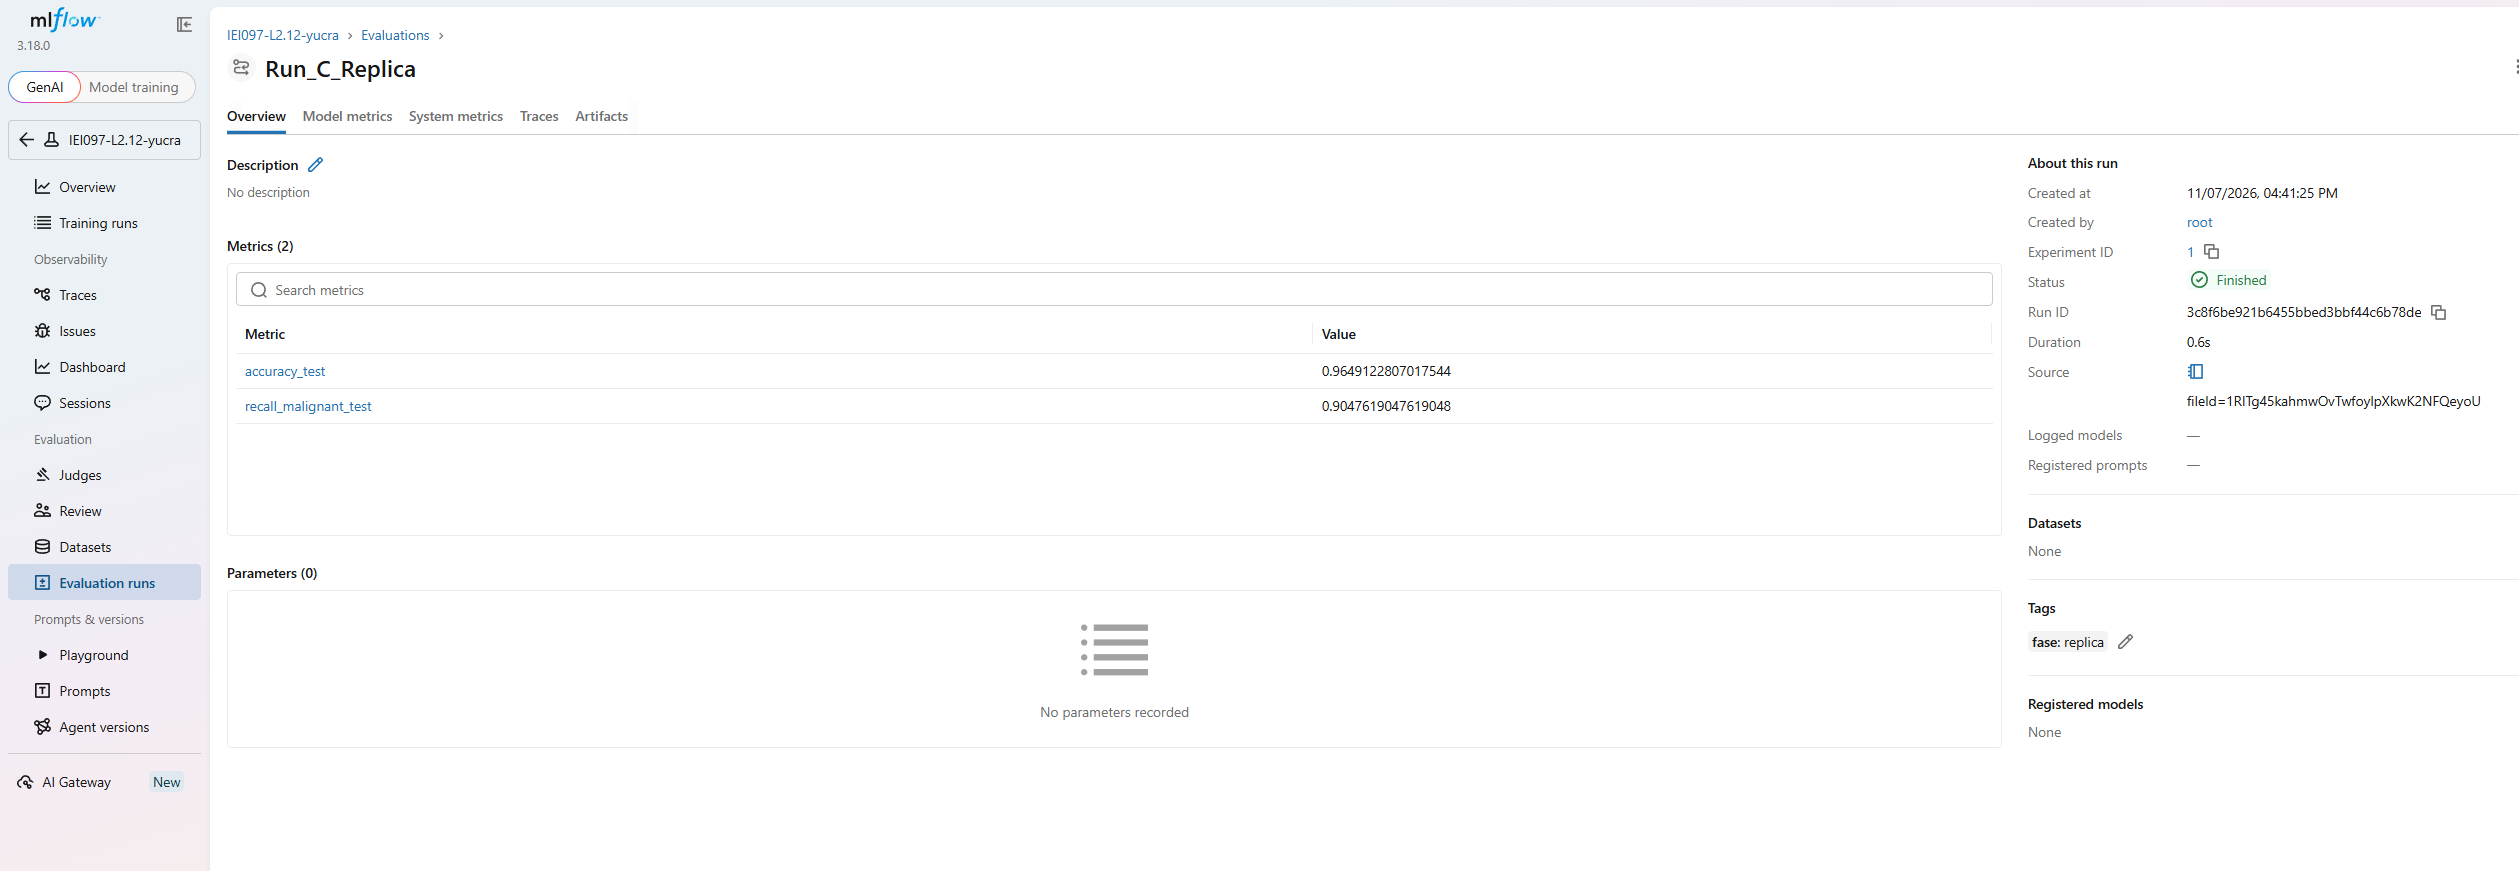

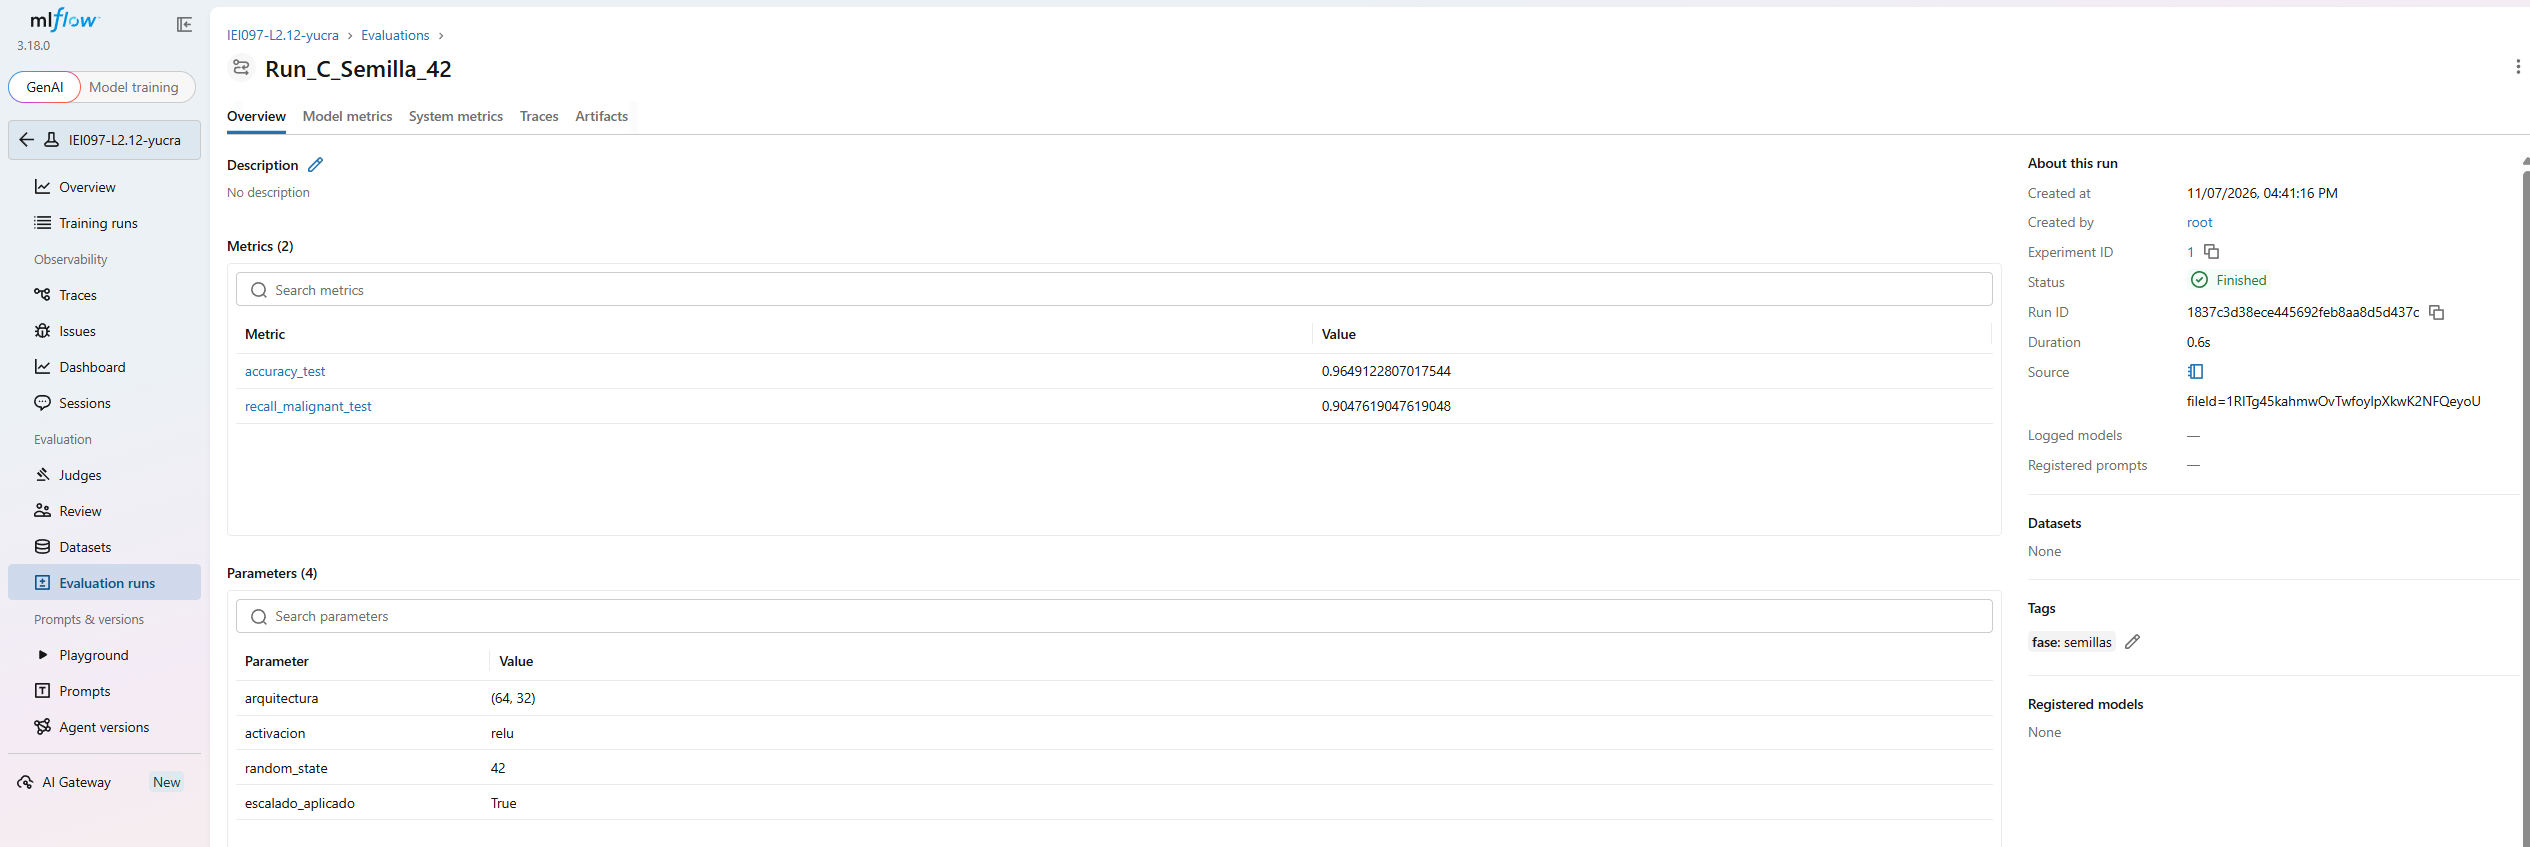


## 📋 Preguntas de Cierre



### 1. ¿Qué cambió al escalar las variables?
* **Evidencia:** El *Run_A_No_Escalado* obtuvo Accuracy de **0.9298** y Recall de **0.8571** en 137 épocas. El *Run_B_Si_Escalado* subió a **0.9737** de Accuracy y **0.9286** de Recall en 341 épocas.
* **Concepto:** `area_mean` tiene un rango 21,282 veces mayor que `smoothness_mean`. Sin escalar, variables grandes dominan el gradiente. El escalado normaliza rangos, estabilizando y optimizando la convergencia del modelo.

### 2. ¿Más capas y neuronas mejoraron el resultado? ¿Cómo lo sabes?
* **R:** No. El modelo monocapa *Run_B* (30 neuronas) logró **0.9737** de Accuracy, mientras que el multicapa *Run_C* `(64, 32)` bajó a **0.9649**. Al cambiar de semilla, el rendimiento de *Run_C* osciló entre **0.9649 y 0.9825**. La variación por azar (semilla) es mayor que la ganancia de agregar más capas.

### 3. Con tus 5 semillas, ¿qué tan grande fue la variación? ¿Qué implica?
* **Variación:** El Accuracy varió **1.76%** y el Recall **4.76%**.
* **Comparación:** Esta oscilación por azar supera la diferencia promedio entre configuraciones.
* **Implicación:** No se puede elegir una configuración como "mejor" con una sola corrida; se requiere evaluar la media y desviación sobre múltiples semillas.

### 4. ¿Falso negativo o falso positivo? ¿Qué métrica priorizar?
* **Error más costoso:** El **falso negativo** (omitir un tumor maligno), ya que retrasa el tratamiento médico de riesgo.
* **Métrica prioritaria:** **Recall (Sensibilidad)** de la clase maligna, para minimizar los falsos negativos y capturar la mayor cantidad de casos reales.

### 5. ¿Qué información de MLflow no tendrías con print() y qué registrarías para replicabilidad?
* **Sin MLflow:** Perderíamos el historial persistente, comparación interactiva de curvas de pérdida, control de versiones y almacenamiento de artefactos (matrices de confusión).
* **Para replicar:** Registraría el archivo `requirements.txt`, la versión del dataset de entrada (o su hash) y las especificaciones del hardware.